In [2]:
import pandas as pd
from google.colab import drive

# drive.mount('/content/drive')
#file_path = '/content/drive/My Drive/ECON FINAL PROJECT/merged_quarterly_data.csv'

ModuleNotFoundError: No module named 'google'

In [ ]:
import pandas as pd
# url = 'https://drive.google.com/file/d/1ZtgfGghu3XOjXssCvTIk8ZUt8Oe9macu/view'
# url = 'https://drive.google.com/uc?id=' + url.split('/')[-2]
url = "/merged_quarterly_data.csv"
data = pd.read_csv(url)

In [ ]:
#data = pd.read_csv(file_path)

In [ ]:
data

,observation_date,CP,INDPRO,WBAA,GPDIC1,GDPC1,WPUFD41312
0,1962-01-01,35.196,24.963267,5.064615,414.522,3758.147,33.000000
1,1962-04-01,35.166,25.205167,5.007692,411.253,3792.149,33.000000
2,1962-07-01,36.205,25.474000,5.046154,418.241,3838.776,33.000000
3,1962-10-01,37.066,25.689067,4.958462,406.004,3851.421,33.000000
4,1963-01-01,36.708,26.163933,4.895385,427.366,3893.482,33.000000
...,...,...,...,...,...,...,...
249,2024-04-01,3468.719,102.863300,5.928462,4381.983,23286.508,217.374667
250,2024-07-01,3443.994,102.711400,5.632308,4392.176,23478.570,218.284667
251,2024-10-01,3689.460,102.402933,5.725385,4315.564,23586.542,219.676000
252,2025-01-01,3335.780,103.430600,5.979231,4547.947,23548.210,221.865333


In [ ]:
print(data.head())

  observation_date      CP     INDPRO      WBAA   GPDIC1     GDPC1  WPUFD41312
0       1962-01-01  35.196  24.963267  5.064615  414.522  3758.147        33.0
1       1962-04-01  35.166  25.205167  5.007692  411.253  3792.149        33.0
2       1962-07-01  36.205  25.474000  5.046154  418.241  3838.776        33.0
3       1962-10-01  37.066  25.689067  4.958462  406.004  3851.421        33.0
4       1963-01-01  36.708  26.163933  4.895385  427.366  3893.482        33.0


In [ ]:
import numpy as np
from statsmodels.tsa.stattools import adfuller
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import linear_reset
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey
import statistics as stats
import scipy.stats as stats
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler

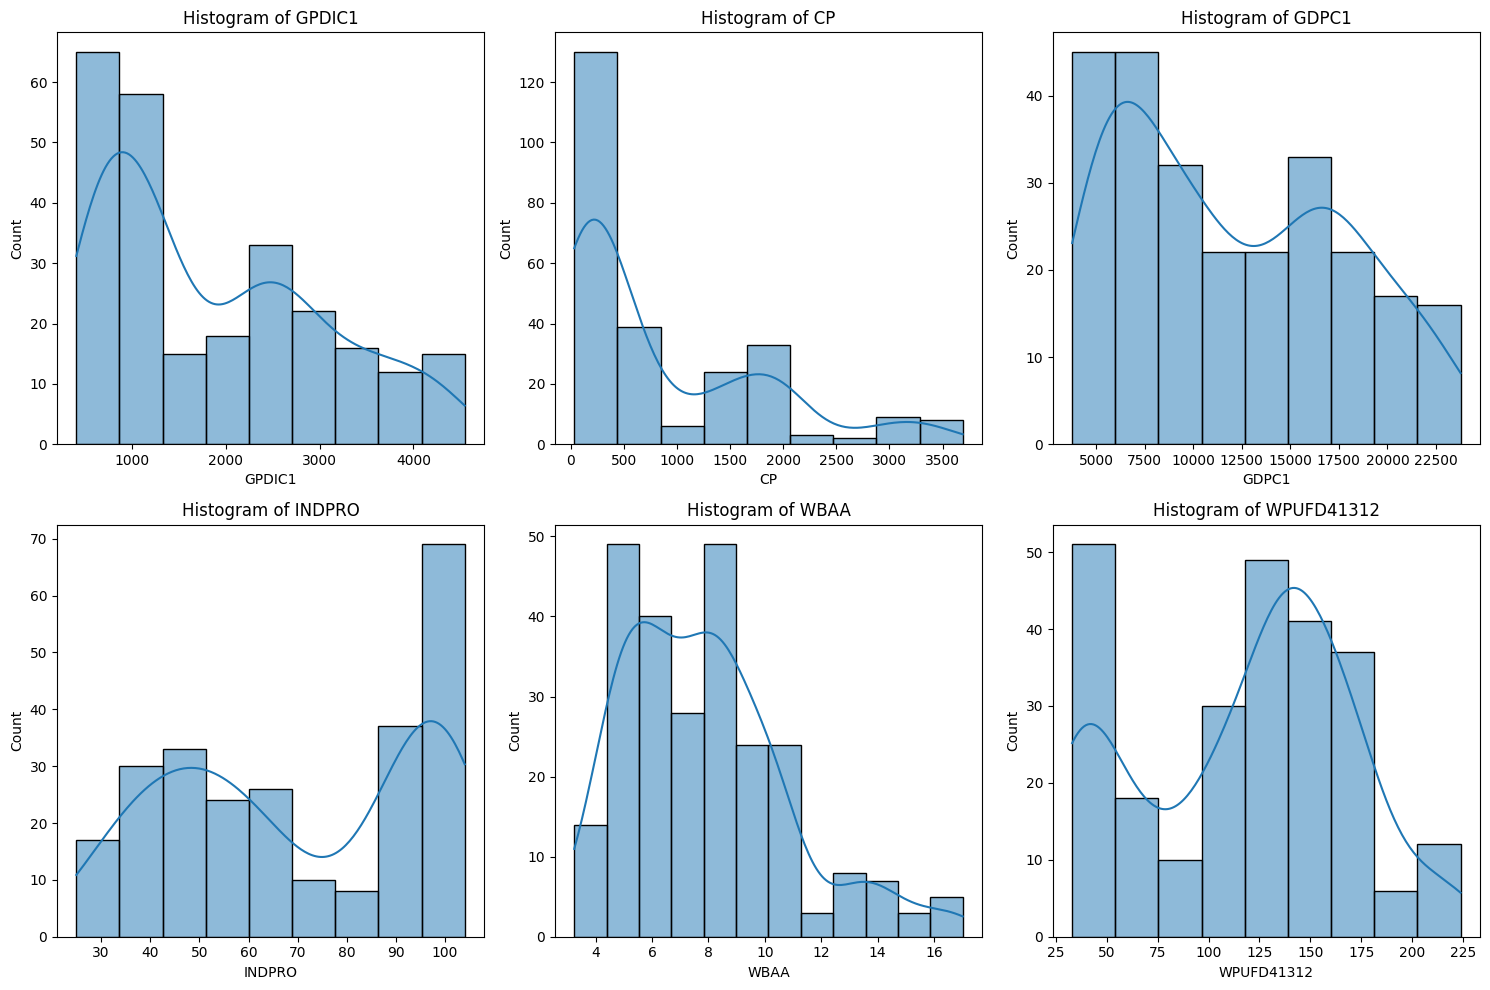

In [ ]:
# A. Histograms (Distribution Analysis) of Original Variables (Before Scaling)
vars_original_list = ['GPDIC1', 'CP', 'GDPC1', 'INDPRO', 'WBAA', 'WPUFD41312']
plt.figure(figsize=(15, 10))
for i, var in enumerate(vars_original_list):
    plt.subplot(2, 3, i + 1)
    sns.histplot(data[var], kde=True)
    plt.title(f'Histogram of {var}')
plt.tight_layout()

In [ ]:
# B. Summary Stats of Original Variables (Before Scaling)
print("\nSummary Statistics:\n")
display(data.describe())


Summary Statistics:



,CP,INDPRO,WBAA,GPDIC1,GDPC1,WPUFD41312
count,254.000000,254.000000,254.000000,254.000000,254.000000,254.000000
mean,845.395291,70.072974,7.873538,1860.976791,11968.934634,117.259490
std,933.648253,25.719200,2.911779,1157.338427,5756.706783,52.330581
min,35.166000,24.963267,3.239231,406.004000,3758.147000,33.000000
25%,167.399250,47.768500,5.616731,839.420250,6780.009000,68.575000
50%,372.275000,65.686150,7.649615,1398.618000,10761.296500,131.783333
75%,1489.702250,96.825908,9.411538,2735.623500,16834.649000,157.025000
max,3689.460000,103.995800,17.013846,4547.947000,23770.976000,223.802333


Most of original variables (before scaling) are right-skewed or left-skewed => Include some of the transformation (log)

In [ ]:
# C. DATA TRANSFORMATION
data_transformed = pd.DataFrame()

# Dependent Variable: Log Difference of Investment Growth
data_transformed['d_log_GPDIC1'] = np.log(data['GPDIC1']).diff()

# Independent Variables: Log Differences (except for rates which are just differenced)
data_transformed['d_log_CP'] = np.log(data['CP']).diff()         # Corporate Profits
data_transformed['d_log_GDPC1'] = np.log(data['GDPC1']).diff()   # Real GDP
data_transformed['d_log_INDPRO'] = np.log(data['INDPRO']).diff() # Industrial Production
data_transformed['d_WBAA'] = data['WBAA'].diff()                 # BAA Yield (Change)
data_transformed['d_WPUFD'] = data['WPUFD41312'].diff() # Producer Price Index

# Add time index
data_transformed['observation_date'] = pd.to_datetime(data['observation_date'])
data_transformed.set_index('observation_date', inplace=True)

# Remove missing values
data_transformed = data_transformed.dropna()
print("Final dataset shape:", data_transformed.shape)

Final dataset shape: (253, 6)


In [ ]:
print("\nSummary Statistics:\n")
display(data_transformed.describe())


Summary Statistics:



,d_log_GPDIC1,d_log_CP,d_log_GDPC1,d_log_INDPRO,d_WBAA,d_WPUFD
count,253.000000,253.000000,253.000000,253.000000,253.000000,253.000000
mean,0.009321,0.018014,0.007291,0.005634,0.004521,0.754159
std,0.039469,0.067015,0.010539,0.017780,0.407368,0.935575
min,-0.175639,-0.507412,-0.082043,-0.136088,-1.896923,-0.833333
25%,-0.007917,-0.005840,0.003479,0.000040,-0.226923,0.133333
50%,0.008766,0.019061,0.007602,0.006854,-0.007692,0.600000
75%,0.029958,0.043761,0.011168,0.013843,0.217692,1.166667
max,0.171547,0.375724,0.074757,0.089128,1.641538,5.412667


In [ ]:
# Drop NaN values created by the diff() operation (the first row)
data_transformed.dropna(inplace=True)

# List of all variables for easy iteration
vars_list = ['d_log_GPDIC1', 'd_log_CP', 'd_log_GDPC1', 'd_log_INDPRO', 'd_WBAA', 'd_WPUFD']

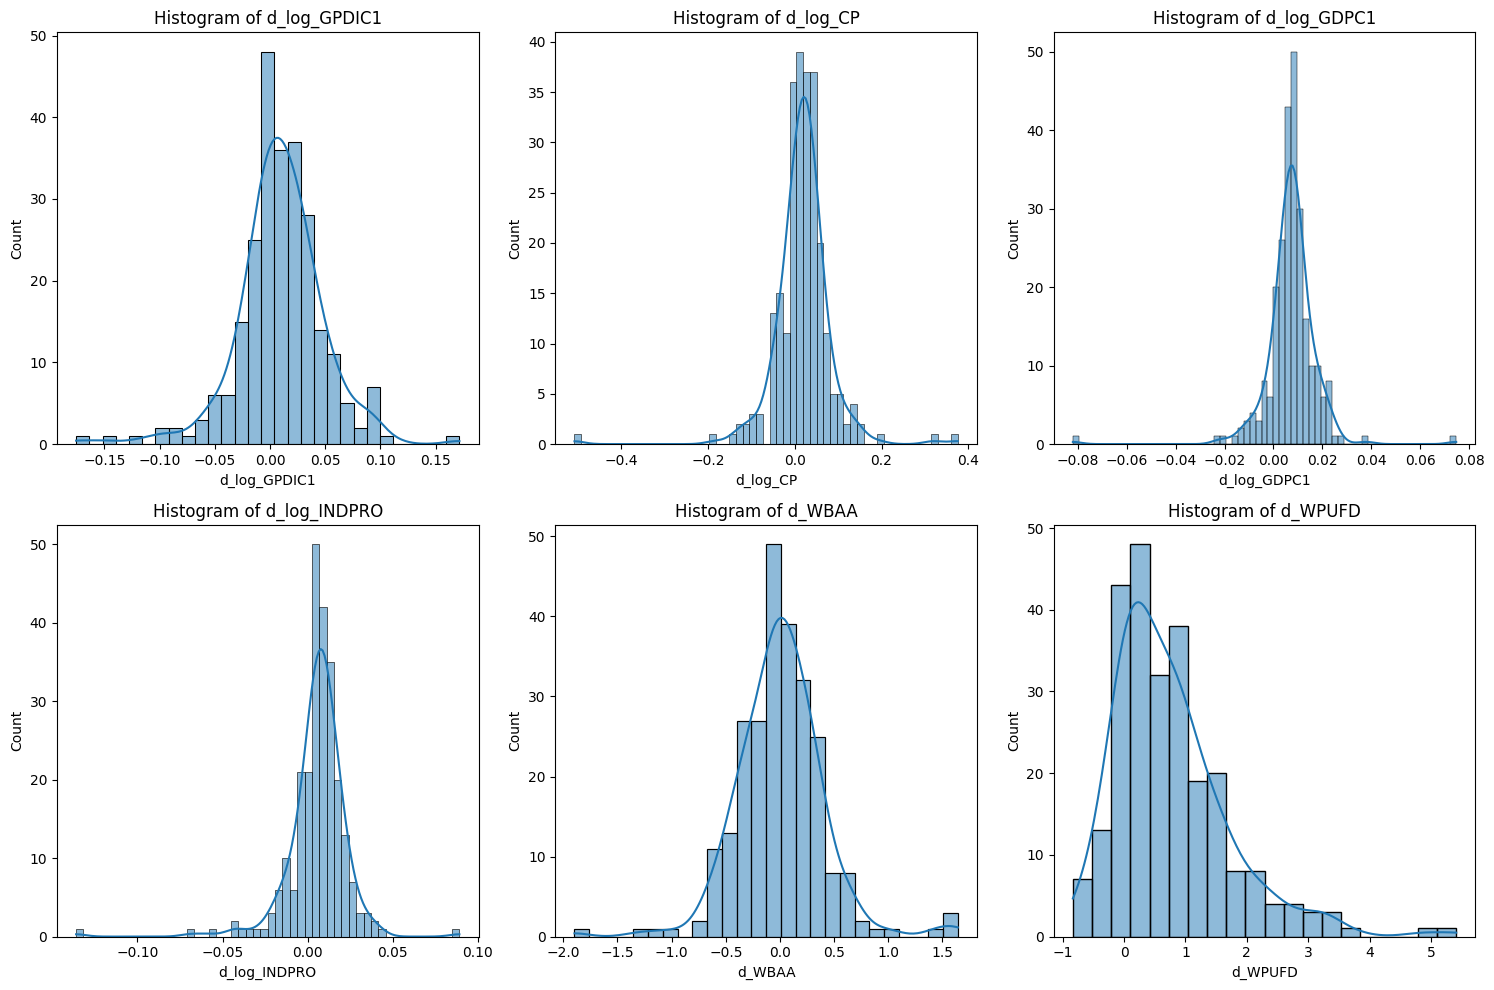

In [ ]:
# D. EXPLORATORY DATA ANALYSIS (EDA) & VISUALIZATION

# D1. Histograms (Distribution Analysis)
plt.figure(figsize=(15, 10))
for i, var in enumerate(vars_list):
    plt.subplot(2, 3, i + 1)
    sns.histplot(data_transformed[var], kde=True)
    plt.title(f'Histogram of {var}')
plt.tight_layout()
# plt.savefig('histograms.png')
# plt.close()


After scaling, most of original variables (before scaling) are normally distributed (except for WPUFD because the original one is approximately normal)

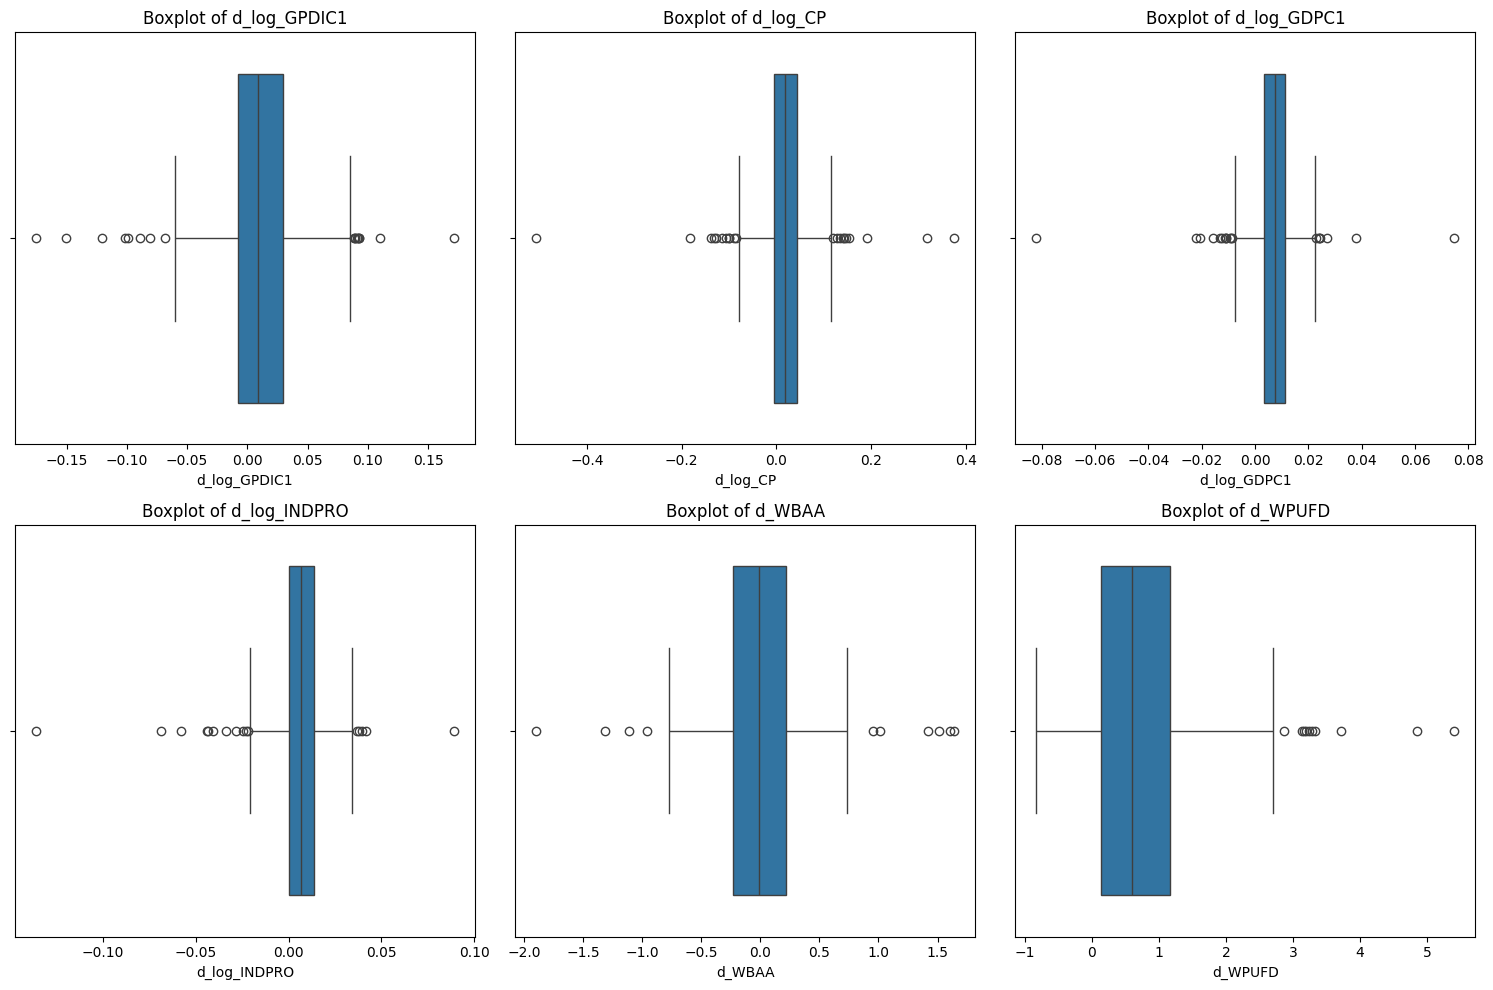

In [ ]:
# D2. Box Plots (Outlier Analysis)
plt.figure(figsize=(15, 10))
for i, var in enumerate(vars_list):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(x=data_transformed[var])
    plt.title(f'Boxplot of {var}')
plt.tight_layout()

Text(0.5, 1.0, 'Correlation Matrix')

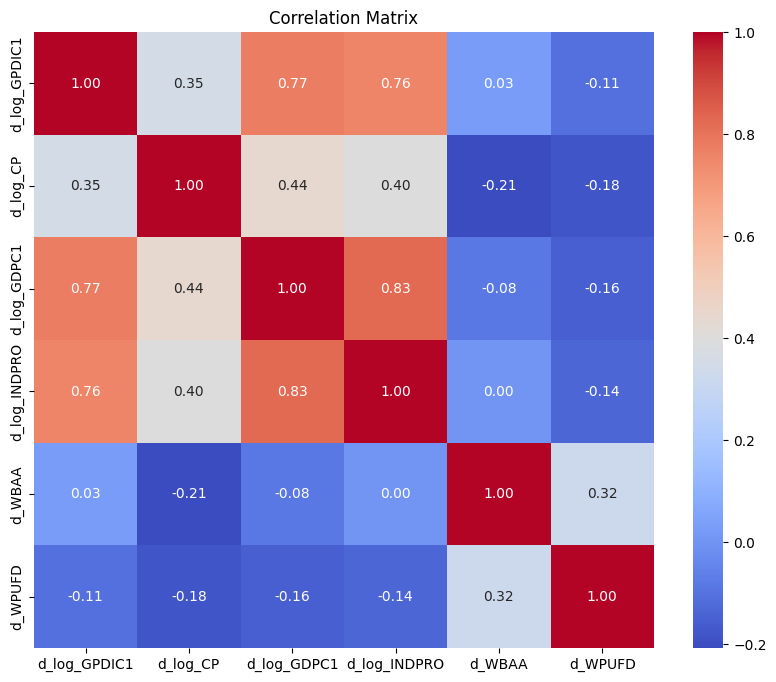

In [ ]:
# D3. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(data_transformed.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
# plt.savefig('correlation_heatmap.png')
# plt.close()

In [ ]:
# E. ADF Test for Stationarity
print("--- Augmented Dickey-Fuller Test Results ---")
for var in vars_list:
    result = adfuller(data_transformed[var])
    print(f"{var}: Statistic={result[0]:.4f}, p-value={result[1]:.4f}")

--- Augmented Dickey-Fuller Test Results ---
d_log_GPDIC1: Statistic=-13.8425, p-value=0.0000
d_log_CP: Statistic=-16.6815, p-value=0.0000
d_log_GDPC1: Statistic=-15.4405, p-value=0.0000
d_log_INDPRO: Statistic=-11.7263, p-value=0.0000
d_WBAA: Statistic=-11.0388, p-value=0.0000
d_WPUFD: Statistic=-2.4235, p-value=0.1352



--- Plotting Scatterplot Matrix (EDA) ---
EDA plot saved to 'eda_pairplot_updated.png'.


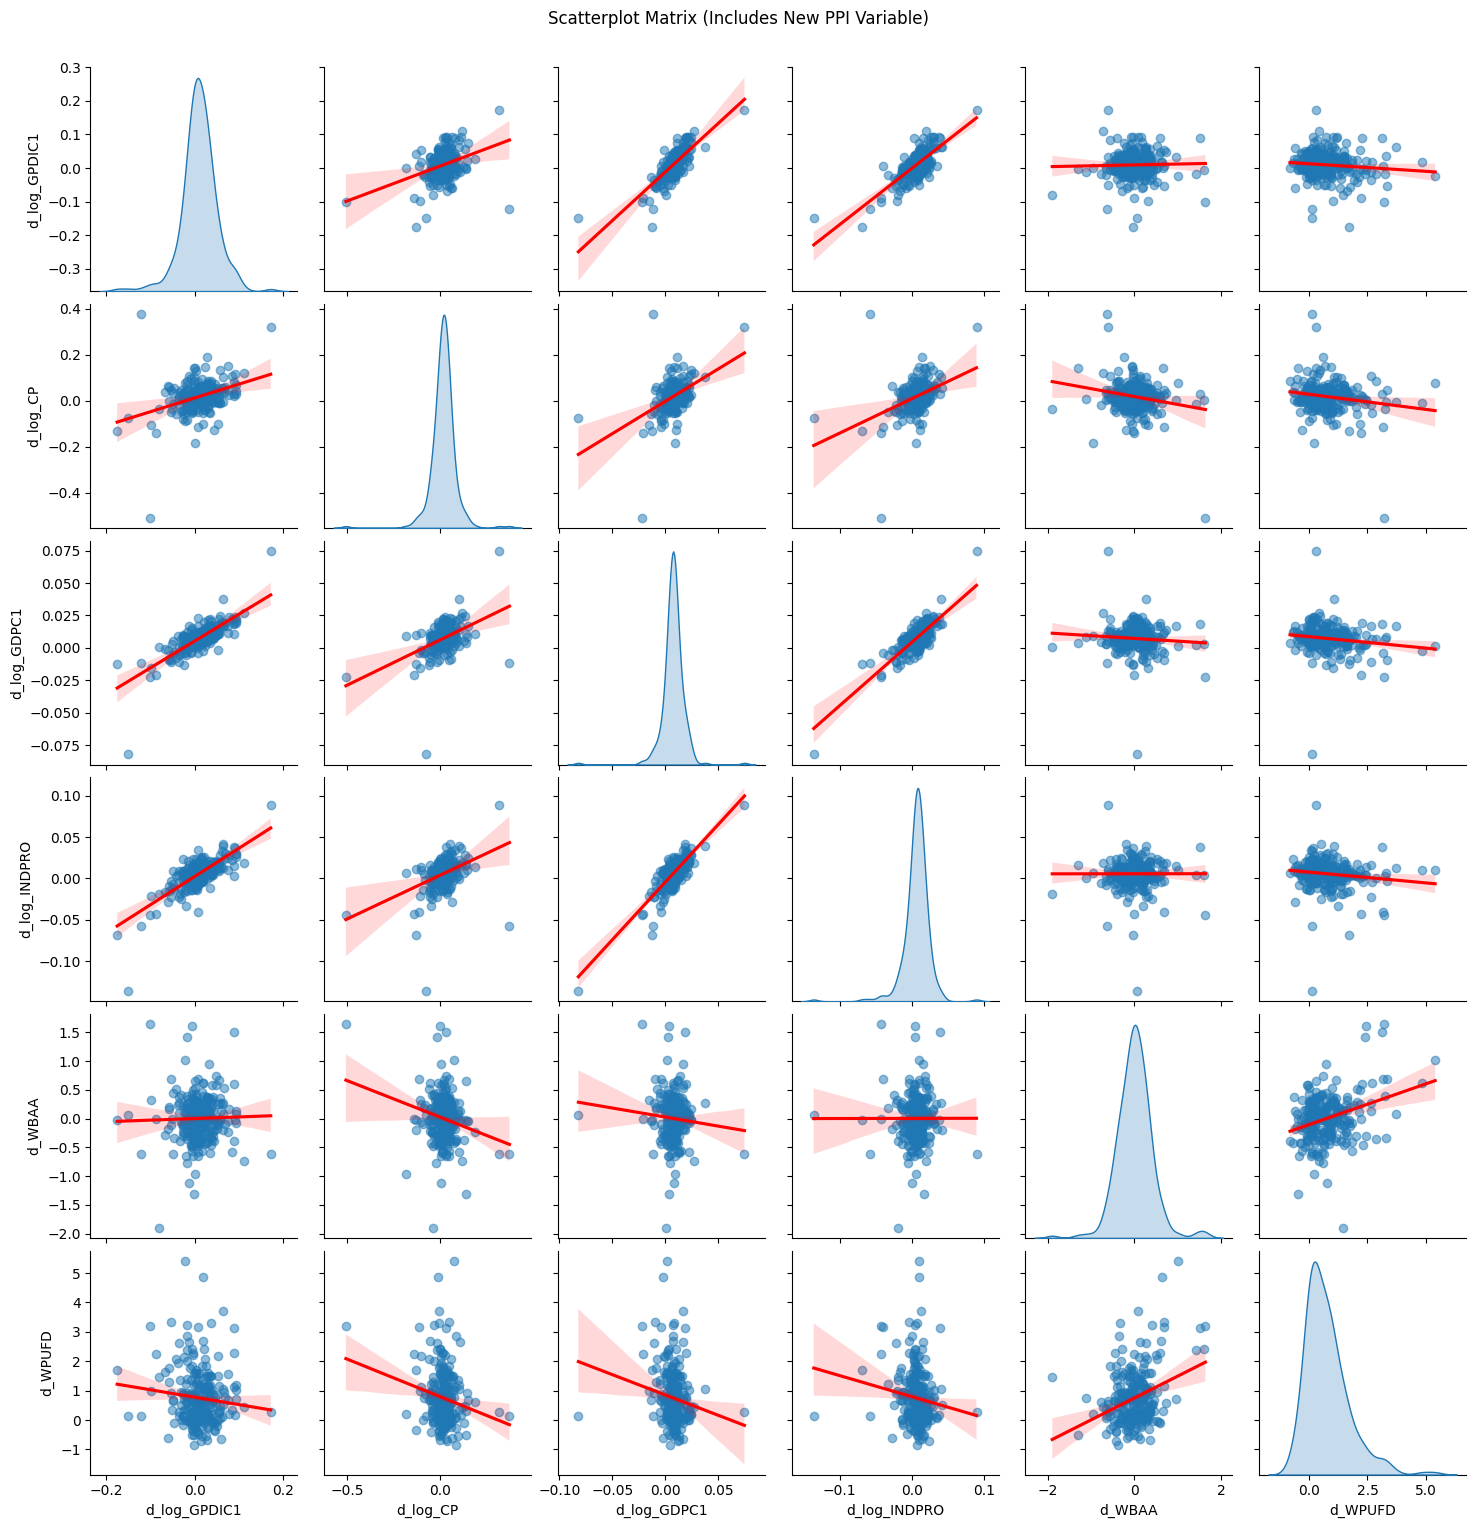

In [ ]:
# F. EXPLORATORY DATA ANALYSIS (EDA)

print("\n--- Plotting Scatterplot Matrix (EDA) ---")
vars_to_plot = ['d_log_GPDIC1', 'd_log_CP', 'd_log_GDPC1',
                'd_log_INDPRO', 'd_WBAA', 'd_WPUFD']

pair_plot = sns.pairplot(
    data_transformed,
    vars=vars_to_plot,
    kind='reg',
    diag_kind='kde',
    plot_kws={'line_kws':{'color':'red'}, 'scatter_kws': {'alpha': 0.5}}
)
pair_plot.fig.suptitle("Scatterplot Matrix (Includes New PPI Variable)", y=1.02)
plt.savefig('eda_pairplot_updated.png')
print("EDA plot saved to 'eda_pairplot_updated.png'.")

In [ ]:
# G. ADD MODELING FEATURES

# Quadratic term
data_transformed["d_log_GDPC1_sq"] = data_transformed["d_log_GDPC1"] ** 2

# Interaction term
data_transformed["interaction_CP_INDPRO"] = (
    data_transformed["d_log_CP"] * data_transformed["d_log_INDPRO"]
)

# Dummy variable (post-2008 financial crisis)
data_transformed["post_2008"] = (data_transformed.index.year >= 2009).astype(int)

In [ ]:
# H. MULTICOLLINEARITY CHECK (VIF)

X_for_vif = data_transformed[["d_log_CP","d_log_GDPC1","d_log_INDPRO","d_WBAA","d_WPUFD"]]
vif_data = pd.DataFrame()
vif_data["Variable"] = X_for_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_for_vif.values, i) for i in range(len(X_for_vif.columns))]
print("\nVariance Inflation Factors:\n")
print(vif_data)



Variance Inflation Factors:

       Variable       VIF
0      d_log_CP  1.398580
1   d_log_GDPC1  3.792504
2  d_log_INDPRO  3.310528
3        d_WBAA  1.160652
4       d_WPUFD  1.253447


# **ALL MODELS**

In [ ]:
# MODEL 1: Basic OLS
model1 = smf.ols("d_log_GPDIC1 ~ d_log_CP + d_log_GDPC1 + d_log_INDPRO + d_WBAA + d_WPUFD",
                 data=data_transformed).fit()
print("\nMODEL 1: Basic OLS\n")
print(model1.summary())


MODEL 1: Basic OLS

                            OLS Regression Results                            
Dep. Variable:           d_log_GPDIC1   R-squared:                       0.648
Model:                            OLS   Adj. R-squared:                  0.640
Method:                 Least Squares   F-statistic:                     90.77
Date:                Mon, 15 Dec 2025   Prob (F-statistic):           6.39e-54
Time:                        00:55:19   Log-Likelihood:                 591.19
No. Observations:                 253   AIC:                            -1170.
Df Residuals:                     247   BIC:                            -1149.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.0083    

In [ ]:
# MODEL 2: Add quadratic term
model2 = smf.ols("d_log_GPDIC1 ~ d_log_CP + d_log_GDPC1 + d_log_GDPC1_sq + d_log_INDPRO + d_WBAA + d_WPUFD",
                 data=data_transformed).fit()
print("\nMODEL 2: Quadratic term added\n")
print(model2.summary())


MODEL 2: Quadratic term added

                            OLS Regression Results                            
Dep. Variable:           d_log_GPDIC1   R-squared:                       0.665
Model:                            OLS   Adj. R-squared:                  0.657
Method:                 Least Squares   F-statistic:                     81.37
Date:                Mon, 15 Dec 2025   Prob (F-statistic):           1.34e-55
Time:                        00:55:19   Log-Likelihood:                 597.59
No. Observations:                 253   AIC:                            -1181.
Df Residuals:                     246   BIC:                            -1156.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept   

In [ ]:
# MODEL 3: Add interaction
model3 = smf.ols("d_log_GPDIC1 ~ d_log_CP + d_log_GDPC1 + d_log_INDPRO + interaction_CP_INDPRO + d_WBAA + d_WPUFD",
                 data=data_transformed).fit()
print("\nMODEL 3: Interaction term\n")
print(model3.summary())


MODEL 3: Interaction term

                            OLS Regression Results                            
Dep. Variable:           d_log_GPDIC1   R-squared:                       0.648
Model:                            OLS   Adj. R-squared:                  0.640
Method:                 Least Squares   F-statistic:                     75.51
Date:                Mon, 15 Dec 2025   Prob (F-statistic):           5.34e-53
Time:                        00:55:19   Log-Likelihood:                 591.38
No. Observations:                 253   AIC:                            -1169.
Df Residuals:                     246   BIC:                            -1144.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
In

In [ ]:
# MODEL 4: Add dummy variable
model4 = smf.ols("d_log_GPDIC1 ~ d_log_CP + d_log_GDPC1 + d_log_INDPRO + d_WBAA + d_WPUFD + post_2008",
                 data=data_transformed).fit()
print("\nMODEL 4: Dummy variable included\n")
print(model4.summary())


MODEL 4: Dummy variable included

                            OLS Regression Results                            
Dep. Variable:           d_log_GPDIC1   R-squared:                       0.659
Model:                            OLS   Adj. R-squared:                  0.650
Method:                 Least Squares   F-statistic:                     79.08
Date:                Mon, 15 Dec 2025   Prob (F-statistic):           1.34e-54
Time:                        00:55:19   Log-Likelihood:                 595.20
No. Observations:                 253   AIC:                            -1176.
Df Residuals:                     246   BIC:                            -1152.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept    

In [ ]:
# ROBUST STANDARD ERRORS
# ------------------------------------------------------------
model1_robust = model1.get_robustcov_results(cov_type='HC1')
print("\nMODEL 1 with Robust Standard Errors:\n")
print(model1_robust.summary())


MODEL 1 with Robust Standard Errors:

                            OLS Regression Results                            
Dep. Variable:           d_log_GPDIC1   R-squared:                       0.648
Model:                            OLS   Adj. R-squared:                  0.640
Method:                 Least Squares   F-statistic:                     16.98
Date:                Mon, 15 Dec 2025   Prob (F-statistic):           2.00e-14
Time:                        00:55:19   Log-Likelihood:                 591.19
No. Observations:                 253   AIC:                            -1170.
Df Residuals:                     247   BIC:                            -1149.
Df Model:                           5                                         
Covariance Type:                  HC1                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept

In [ ]:
# H. HETEROSKEDASTICITY TESTS
bp_test = het_breuschpagan(model1.resid, model1.model.exog)
white_test = het_white(model1.resid, model1.model.exog)

print("\nBreusch-Pagan Test (LM Stat, p-value, F-stat, F p-value):")
print(bp_test)

print("\nWhite Test (LM Stat, p-value, F-stat, F p-value):")
print(white_test)


Breusch-Pagan Test (LM Stat, p-value, F-stat, F p-value):
(np.float64(57.104093981584455), np.float64(4.813191601339697e-11), np.float64(14.400210295487671), np.float64(2.230034250592188e-12))

White Test (LM Stat, p-value, F-stat, F p-value):
(np.float64(162.1934875910714), np.float64(2.8298157783475736e-24), np.float64(20.71926788228279), np.float64(7.002244961454122e-41))


In [ ]:
# MODEL 5: Standardized Regression
scaler = StandardScaler()
Z = scaler.fit_transform(data_transformed.drop(columns=["d_log_GPDIC1"]))
Z = pd.DataFrame(Z, index=data_transformed.index, columns=data_transformed.drop(columns=["d_log_GPDIC1"]).columns)

Z["d_log_GPDIC1"] = data_transformed["d_log_GPDIC1"]

model_std = smf.ols(
    "d_log_GPDIC1 ~ d_log_CP + d_log_GDPC1 + d_log_INDPRO + d_WBAA + d_WPUFD",
    data=Z
).fit()

print("\nMODEL 5: Standardized Regression\n")
print(model_std.summary())


MODEL 5: Standardized Regression

                            OLS Regression Results                            
Dep. Variable:           d_log_GPDIC1   R-squared:                       0.648
Model:                            OLS   Adj. R-squared:                  0.640
Method:                 Least Squares   F-statistic:                     90.77
Date:                Mon, 15 Dec 2025   Prob (F-statistic):           6.39e-54
Time:                        00:55:19   Log-Likelihood:                 591.19
No. Observations:                 253   AIC:                            -1170.
Df Residuals:                     247   BIC:                            -1149.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept    

In [ ]:
# ADJUSTED R² COMPARISON TABLE

comparison = pd.DataFrame({
    "Model": ["Model 1 Basic",
              "Model 2 Quadratic",
              "Model 3 Interaction",
              "Model 4 Dummy",
              "Model 5 Standardized"],
    "Adjusted R²": [
        model1.rsquared_adj,
        model2.rsquared_adj,
        model3.rsquared_adj,
        model4.rsquared_adj,
        model_std.rsquared_adj
    ]
})

print("\nAdjusted R² Comparison Across Models:\n")
print(comparison)


Adjusted R² Comparison Across Models:

                  Model  Adjusted R²
0         Model 1 Basic     0.640426
1     Model 2 Quadratic     0.656771
2   Model 3 Interaction     0.639506
3         Model 4 Dummy     0.650244
4  Model 5 Standardized     0.640426


# **Autocorrelation (Breusch-Godfrey Test)**

In [ ]:
# (MODEL 1)
# Using 4 lags for quarterly data
bg_test_stat, bg_pval, bg_fstat, bg_fpval = acorr_breusch_godfrey(model1, nlags=4)
print("\n--- Breusch-Godfrey Test (Autocorrelation) ---")
print(f"LM Statistic p-value: {bg_pval:.4f}")


--- Breusch-Godfrey Test (Autocorrelation) ---
LM Statistic p-value: 0.2190


In [ ]:
# (MODEL 2)
# Using 4 lags for quarterly data
bg_test_stat, bg_pval, bg_fstat, bg_fpval = acorr_breusch_godfrey(model2, nlags=4)
print("\n--- Breusch-Godfrey Test (Autocorrelation) ---")
print(f"LM Statistic p-value: {bg_pval:.4f}")


--- Breusch-Godfrey Test (Autocorrelation) ---
LM Statistic p-value: 0.0189


In [ ]:
# (MODEL 3)
# Using 4 lags for quarterly data
bg_test_stat, bg_pval, bg_fstat, bg_fpval = acorr_breusch_godfrey(model3, nlags=4)
print("\n--- Breusch-Godfrey Test (Autocorrelation) ---")
print(f"LM Statistic p-value: {bg_pval:.4f}")


--- Breusch-Godfrey Test (Autocorrelation) ---
LM Statistic p-value: 0.1288


In [ ]:
# (MODEL 4)
# Using 4 lags for quarterly data
bg_test_stat, bg_pval, bg_fstat, bg_fpval = acorr_breusch_godfrey(model4, nlags=4)
print("\n--- Breusch-Godfrey Test (Autocorrelation) ---")
print(f"LM Statistic p-value: {bg_pval:.4f}")


--- Breusch-Godfrey Test (Autocorrelation) ---
LM Statistic p-value: 0.1052


In [ ]:
# (MODEL 5)
# Using 4 lags for quarterly data
bg_test_stat, bg_pval, bg_fstat, bg_fpval = acorr_breusch_godfrey(model_std, nlags=4)
print("\n--- Breusch-Godfrey Test (Autocorrelation) ---")
print(f"LM Statistic p-value: {bg_pval:.4f}")


--- Breusch-Godfrey Test (Autocorrelation) ---
LM Statistic p-value: 0.2190


# **Normality (Shapiro-Wilk)**

In [ ]:
# (MODEL 1)
shapiro_test = stats.shapiro(model1.resid)
print(f"\nShapiro-Wilk (Normality) p-value (model 1): {shapiro_test.pvalue:.4f}")


Shapiro-Wilk (Normality) p-value (model 1): 0.0002


In [ ]:
# (MODEL 2)
shapiro_test = stats.shapiro(model2.resid)
print(f"\nShapiro-Wilk (Normality) p-value (model 2): {shapiro_test.pvalue:.4f}")


Shapiro-Wilk (Normality) p-value (model 2): 0.0536


In [ ]:
# (MODEL 3)
shapiro_test = stats.shapiro(model3.resid)
print(f"\nShapiro-Wilk (Normality) p-value (model 3): {shapiro_test.pvalue:.4f}")


Shapiro-Wilk (Normality) p-value (model 3): 0.0005


In [ ]:
# (MODEL 4)
shapiro_test = stats.shapiro(model4.resid)
print(f"\nShapiro-Wilk (Normality) p-value (model 4): {shapiro_test.pvalue:.4f}")


Shapiro-Wilk (Normality) p-value (model 4): 0.0006


In [ ]:
# (MODEL 5)
shapiro_test = stats.shapiro(model_std.resid)
print(f"\nShapiro-Wilk (Normality) p-value (model 5): {shapiro_test.pvalue:.4f}")


Shapiro-Wilk (Normality) p-value (model 5): 0.0002


# **Q-Q Plot**

Q-Q plot saved to 'qqplot_updated.png'.


<Figure size 640x480 with 0 Axes>

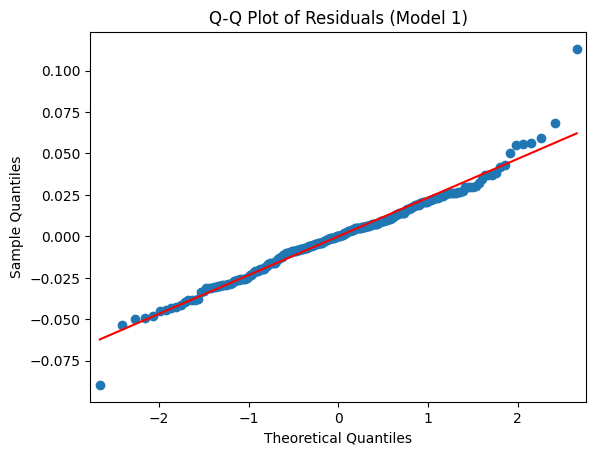

In [ ]:
# (MODEL 1)
plt.figure()
sm.qqplot(model1.resid, line='s')
plt.title("Q-Q Plot of Residuals (Model 1)")
plt.savefig('qqplot_updated.png')
print("Q-Q plot saved to 'qqplot_updated.png'.")

Q-Q plot saved to 'qqplot_updated.png'.


<Figure size 640x480 with 0 Axes>

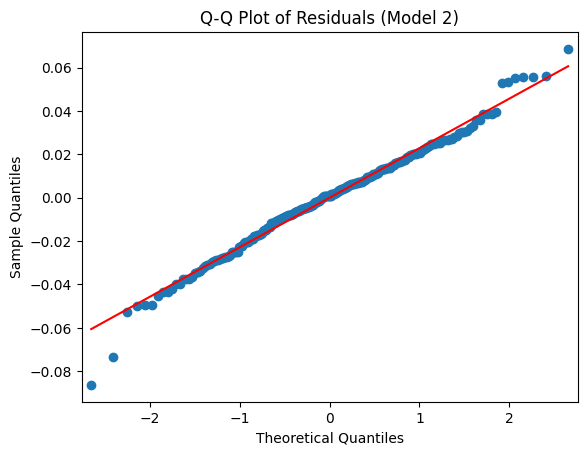

In [ ]:
# (MODEL 2)
plt.figure()
sm.qqplot(model2.resid, line='s')
plt.title("Q-Q Plot of Residuals (Model 2)")
plt.savefig('qqplot_updated.png')
print("Q-Q plot saved to 'qqplot_updated.png'.")

Q-Q plot saved to 'qqplot_updated.png'.


<Figure size 640x480 with 0 Axes>

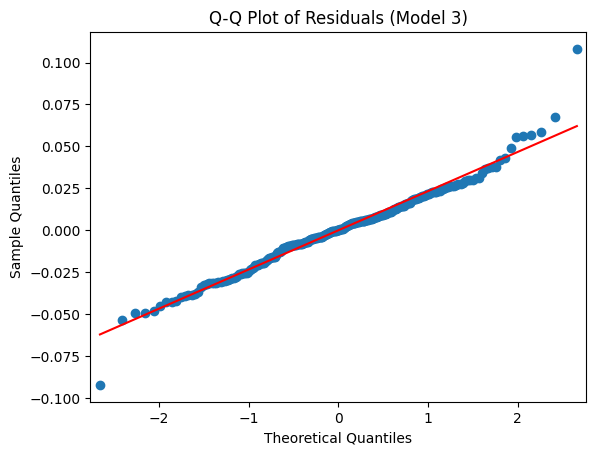

In [ ]:
# (MODEL 3)
plt.figure()
sm.qqplot(model3.resid, line='s')
plt.title("Q-Q Plot of Residuals (Model 3)")
plt.savefig('qqplot_updated.png')
print("Q-Q plot saved to 'qqplot_updated.png'.")

Q-Q plot saved to 'qqplot_updated.png'.


<Figure size 640x480 with 0 Axes>

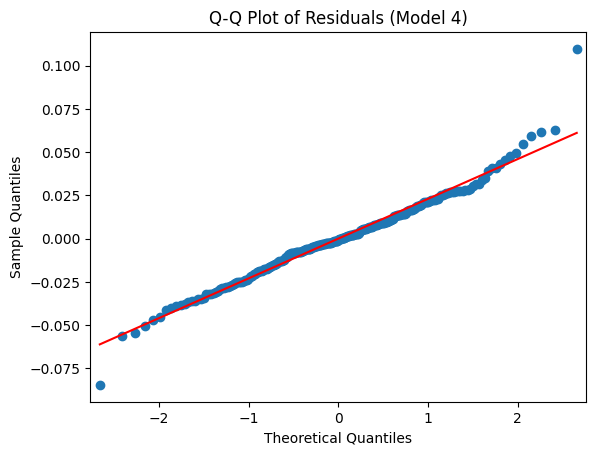

In [ ]:
# (MODEL 4)
plt.figure()
sm.qqplot(model4.resid, line='s')
plt.title("Q-Q Plot of Residuals (Model 4)")
plt.savefig('qqplot_updated.png')
print("Q-Q plot saved to 'qqplot_updated.png'.")

Q-Q plot saved to 'qqplot_updated.png'.


<Figure size 640x480 with 0 Axes>

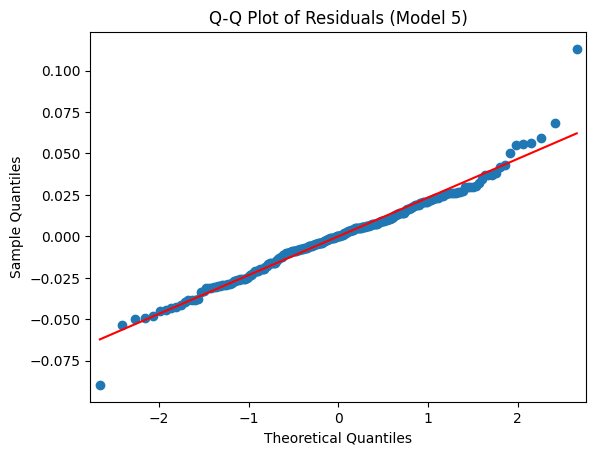

In [ ]:
# (MODEL 5)
plt.figure()
sm.qqplot(model_std.resid, line='s')
plt.title("Q-Q Plot of Residuals (Model 5)")
plt.savefig('qqplot_updated.png')
print("Q-Q plot saved to 'qqplot_updated.png'.")

# **Forecasting**
Forecast investment growth (`d_log_GPDIC1`) with **Model 4**, then evaluate the forecasts:
1. **K1 – Accuracy test**: rolling one-quarter-ahead forecasts for 2010–2019 and 2021–2025, against simple benchmarks.
2. **K2 – Forecast the future**: predict the drivers with a VAR, then feed them into Model 4 (next 8 quarters).
3. **K3 – Prediction distribution**: simulate 10,000 possible futures to get the full range of outcomes.
4. **K4 – Backtest K2/K3**: rerun K2/K3 from past quarters and check accuracy, interval coverage and P(decline), 1–4 quarters ahead.
5. **K5 – Real-data check**: compare the forecasts with actual BEA data released after the dataset ends (2025Q2).

RMSE (percentage points, lower is better):


,2010-2019 (40 quarters),2021-2025 (18 quarters)
Model 4 (ex-post),1.44,3.09
Model 4 + VAR (ex-ante),2.04,2.39
AR(1),2.05,2.70
Historical mean,2.03,2.62


2010-2019 (40 quarters): Model 4 + VAR vs mean, Diebold-Mariano p-value = 0.982
2021-2025 (18 quarters): Model 4 + VAR vs mean, Diebold-Mariano p-value = 0.373


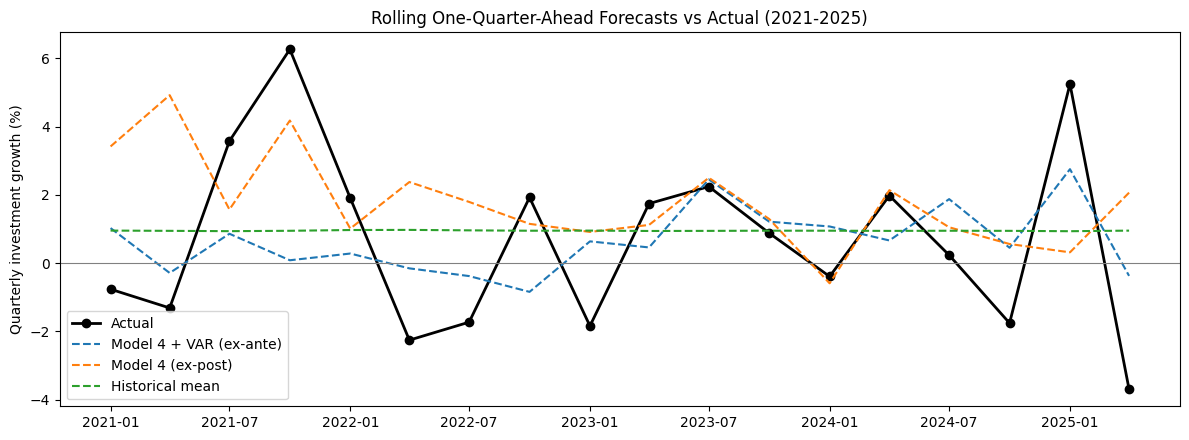

In [42]:
# K1. FORECAST ACCURACY: rolling one-quarter-ahead test
# For each test quarter: refit on all earlier data, forecast that quarter, compare with the actual value.
#   Model 4 (ex-post)        -> uses the ACTUAL drivers (best case, not a real forecast)
#   Model 4 + VAR (ex-ante)  -> drivers forecast by a VAR: a real forecast, same approach as K2/K3
#   AR(1), Historical mean   -> simple benchmarks
from statsmodels.tsa.api import VAR
from statsmodels.tsa.ar_model import AutoReg
import warnings
warnings.filterwarnings("ignore", message="No frequency information")

formula = "d_log_GPDIC1 ~ d_log_CP + d_log_GDPC1 + d_log_INDPRO + d_WBAA + d_WPUFD + post_2008"
drivers = ["d_log_CP", "d_log_GDPC1", "d_log_INDPRO", "d_WBAA", "d_WPUFD"]

rows = []
for date in data_transformed.loc["2010-01-01":].index:
    train = data_transformed.loc[:date].iloc[:-1]
    actual = data_transformed.loc[[date]]
    m4 = smf.ols(formula, data=train).fit()
    var_fit = VAR(train[drivers]).fit(maxlags=4, ic="aic")
    x_hat = pd.DataFrame(var_fit.forecast(train[drivers].values[-var_fit.k_ar:], steps=1), columns=drivers).assign(post_2008=1)
    rows.append({"date": date, "Actual": actual["d_log_GPDIC1"].iloc[0],
                 "Model 4 (ex-post)": m4.predict(actual).iloc[0],
                 "Model 4 + VAR (ex-ante)": m4.predict(x_hat).iloc[0],
                 "AR(1)": AutoReg(train["d_log_GPDIC1"].values, lags=1).fit().forecast(1)[0],
                 "Historical mean": train["d_log_GPDIC1"].mean()})
backtest = pd.DataFrame(rows).set_index("date")

# Score two periods separately; 2020 (COVID) is excluded because its huge swings dominate every metric
periods = {"2010-2019 (40 quarters)": backtest.loc["2010":"2019"], "2021-2025 (18 quarters)": backtest.loc["2021":]}
rmse = pd.DataFrame({name: 100 * np.sqrt((b.drop(columns="Actual").sub(b["Actual"], axis=0) ** 2).mean())
                     for name, b in periods.items()})
print("RMSE (percentage points, lower is better):")
display(rmse.round(2))

# Is Model 4 + VAR significantly better than the historical mean? (Diebold-Mariano test)
for name, b in periods.items():
    loss_diff = (b["Model 4 + VAR (ex-ante)"] - b["Actual"]) ** 2 - (b["Historical mean"] - b["Actual"]) ** 2
    print(f"{name}: Model 4 + VAR vs mean, Diebold-Mariano p-value = {stats.ttest_1samp(loss_diff, 0).pvalue:.3f}")

recent = backtest.loc["2021":]
plt.figure(figsize=(12, 4.5))
plt.plot(recent.index, 100 * recent["Actual"], "k-o", lw=2, label="Actual")
for col in ["Model 4 + VAR (ex-ante)", "Model 4 (ex-post)", "Historical mean"]:
    plt.plot(recent.index, 100 * recent[col], "--", label=col)
plt.axhline(0, color="grey", lw=0.8)
plt.ylabel("Quarterly investment growth (%)")
plt.title("Rolling One-Quarter-Ahead Forecasts vs Actual (2021-2025)")
plt.legend()
plt.tight_layout()


In [43]:
# K2. FORECAST THE NEXT 8 QUARTERS
# Model 4 needs future driver values, so we forecast them with a VAR
from statsmodels.tsa.api import VAR
import warnings
warnings.filterwarnings("ignore", message="No frequency information")

drivers = ["d_log_CP", "d_log_GDPC1", "d_log_INDPRO", "d_WBAA", "d_WPUFD"]
H = 8
var_model = VAR(data_transformed[drivers]).fit(maxlags=4, ic="aic")
last_obs = data_transformed[drivers].values[-var_model.k_ar:]

future_dates = pd.date_range(data_transformed.index[-1], periods=H + 1, freq="QS")[1:]
future_X = pd.DataFrame(var_model.forecast(last_obs, steps=H), index=future_dates, columns=drivers)
future_X["post_2008"] = 1

forecast = model4.get_prediction(future_X).summary_frame(alpha=0.05)
forecast.index = future_dates
print("Investment growth forecast (%):")
display((100 * forecast[["mean", "obs_ci_lower", "obs_ci_upper"]]).round(2))


Investment growth forecast (%):


,mean,obs_ci_lower,obs_ci_upper
2025-07-01,0.35,-4.29,4.99
2025-10-01,0.77,-3.87,5.40
2026-01-01,1.08,-3.56,5.71
2026-04-01,0.99,-3.65,5.62
2026-07-01,0.78,-3.85,5.42
2026-10-01,1.21,-3.43,5.84
2027-01-01,1.35,-3.28,5.99
2027-04-01,1.25,-3.38,5.89


Next quarter: median 0.34%, 90% interval [-5.96%, 6.78%], P(decline) = 46%


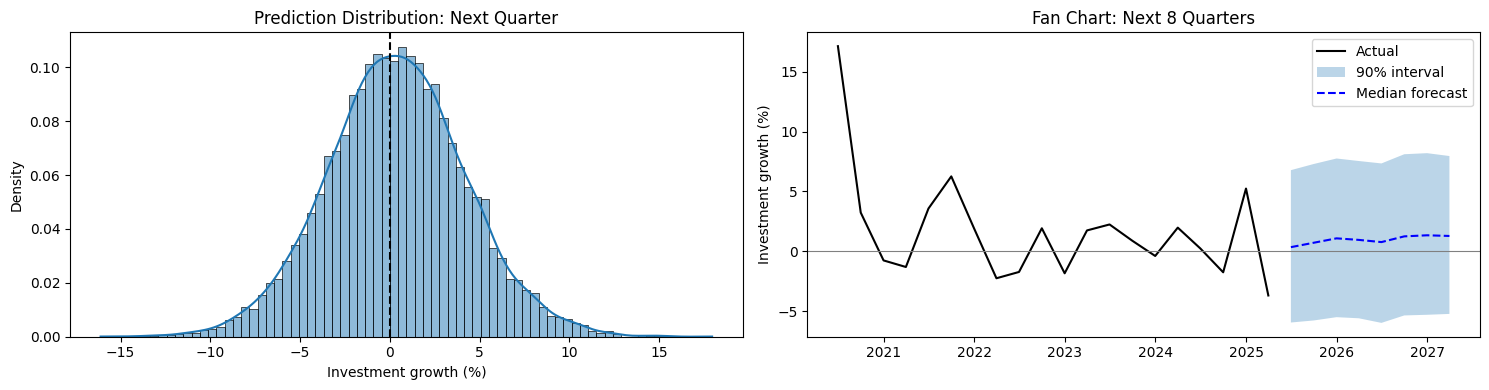

In [44]:
# K3. PREDICTION DISTRIBUTION (10,000 simulations)
# Each simulation = a random driver path from the VAR + random past Model 4 errors
N = 10_000
p = var_model.k_ar
driver_paths = var_model.simulate_var(steps=p + H, initial_values=last_obs, nsimulations=N, seed=42)[:, p:, :]

X_sim = np.concatenate([np.ones((N, H, 1)), driver_paths, np.ones((N, H, 1))], axis=2)  # intercept, drivers, post_2008
errors = np.random.default_rng(42).choice(model4.resid, size=(N, H))
sim_growth = 100 * (X_sim @ model4.params.values + errors)

next_q = sim_growth[:, 0]
print(f"Next quarter: median {np.median(next_q):.2f}%, "
      f"90% interval [{np.percentile(next_q, 5):.2f}%, {np.percentile(next_q, 95):.2f}%], "
      f"P(decline) = {(next_q < 0).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(next_q, kde=True, stat="density", ax=axes[0])
axes[0].axvline(0, color="k", ls="--")
axes[0].set_title("Prediction Distribution: Next Quarter")
axes[0].set_xlabel("Investment growth (%)")

recent = 100 * data_transformed["d_log_GPDIC1"].iloc[-20:]
axes[1].plot(recent.index, recent, "k-", label="Actual")
axes[1].fill_between(future_dates, np.percentile(sim_growth, 5, axis=0), np.percentile(sim_growth, 95, axis=0), alpha=0.3, label="90% interval")
axes[1].plot(future_dates, np.median(sim_growth, axis=0), "b--", label="Median forecast")
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_title("Fan Chart: Next 8 Quarters")
axes[1].set_ylabel("Investment growth (%)")
axes[1].legend()
plt.tight_layout()


In [45]:
# K4. EVALUATE K2 AND K3 WITH A BACKTEST (1 to 4 quarters ahead)
# Rerun the K2/K3 forecast from each past quarter, using only data available at that time, then score it:
#   RMSE: K2 forecast vs historical mean (lower is better)
#   Coverage: how often the actual value falls inside the K2 95% / K3 90% interval (should be ~95% / ~90%)
#   Brier score: accuracy of K3's P(decline) vs a naive P(decline) = share of past declines (lower is better)
H_TEST, N_TEST = 4, 2000
dt = data_transformed
rows = []
for pos in range(dt.index.get_loc(pd.Timestamp("2010-01-01")), len(dt)):
    train = dt.iloc[:pos]
    m4 = smf.ols(formula, data=train).fit()
    var_fit = VAR(train[drivers]).fit(maxlags=4, ic="aic")
    p, last = var_fit.k_ar, train[drivers].values[-var_fit.k_ar:]
    steps = min(H_TEST, len(dt) - pos)

    X_point = pd.DataFrame(var_fit.forecast(last, steps), columns=drivers).assign(post_2008=1)
    k2 = m4.get_prediction(X_point).summary_frame(alpha=0.05)
    paths = var_fit.simulate_var(steps=p + steps, initial_values=last, nsimulations=N_TEST, seed=pos)[:, p:, :]
    X_s = np.concatenate([np.ones((N_TEST, steps, 1)), paths, np.ones((N_TEST, steps, 1))], axis=2)
    sims = X_s @ m4.params.values + np.random.default_rng(pos).choice(m4.resid.values, size=(N_TEST, steps))

    for h in range(steps):
        rows.append({"target": dt.index[pos + h], "h": h + 1, "actual": dt["d_log_GPDIC1"].iloc[pos + h],
                     "k2": k2["mean"].iloc[h], "k2_lo": k2["obs_ci_lower"].iloc[h], "k2_hi": k2["obs_ci_upper"].iloc[h],
                     "k3_lo": np.percentile(sims[:, h], 5), "k3_hi": np.percentile(sims[:, h], 95),
                     "p_decline": (sims[:, h] < 0).mean(),
                     "mean": train["d_log_GPDIC1"].mean(), "naive_p": (train["d_log_GPDIC1"] < 0).mean()})

bt = pd.DataFrame(rows)
bt = bt[bt["target"].dt.year != 2020]   # exclude COVID quarters from scoring
bt["period"] = np.where(bt["target"].dt.year < 2020, "2010-2019", "2021-2025")

decline = (bt["actual"] < 0).astype(float)
bt["RMSE K2 (pp)"] = (bt["actual"] - bt["k2"]) ** 2
bt["RMSE mean (pp)"] = (bt["actual"] - bt["mean"]) ** 2
bt["K2 95% coverage"] = bt["actual"].between(bt["k2_lo"], bt["k2_hi"])
bt["K3 90% coverage"] = bt["actual"].between(bt["k3_lo"], bt["k3_hi"])
bt["Brier K3"] = (bt["p_decline"] - decline) ** 2
bt["Brier naive"] = (bt["naive_p"] - decline) ** 2

k4 = bt.groupby(["period", "h"])[["RMSE K2 (pp)", "RMSE mean (pp)", "K2 95% coverage",
                                  "K3 90% coverage", "Brier K3", "Brier naive"]].mean()
k4[["RMSE K2 (pp)", "RMSE mean (pp)"]] = 100 * np.sqrt(k4[["RMSE K2 (pp)", "RMSE mean (pp)"]])
print("Backtest of K2/K3 by period and forecast horizon (h = quarters ahead):")
display(k4.round(3))


Backtest of K2/K3 by period and forecast horizon (h = quarters ahead):


RMSE K2 (pp)  RMSE mean (pp)  K2 95% coverage  K3 90% coverage  \
period    h                                                                   
2010-2019 1         2.039           2.031            0.950            1.000   
          2         2.451           2.048            0.897            1.000   
          3         2.460           1.957            0.947            1.000   
          4         2.606           1.898            0.946            1.000   
2021-2025 1         2.392           2.623            0.944            1.000   
          2         2.954           2.621            0.944            0.944   
          3         2.851           2.616            0.889            1.000   
          4         2.797           2.614            0.944            1.000   

             Brier K3  Brier naive  
period    h                         
2010-2019 1     0.183        0.204  
          2     0.210        0.206  
          3     0.212        0.207  
          4     0.215        0.208  
2021-2025 1     0.220        0.254  
          2     0.269        0.253  
          3     0.234        0.253  
          4     0.262        0.253

Actual data available for 4 of the 8 forecast quarters



,Actual (%),K2 forecast (%),K3 90% low (%),K3 90% high (%),K3 P(decline),Inside K3 90%?
2025-07-01,0.18,0.35,-5.96,6.78,0.46,True
2025-10-01,0.27,0.77,-5.79,7.30,0.43,True
2026-01-01,1.73,1.08,-5.51,7.76,0.40,True
2026-04-01,1.14,0.99,-5.61,7.55,0.40,True


RMSE - K2 forecast: 0.42 pp | Historical mean (0.93%): 0.65 pp


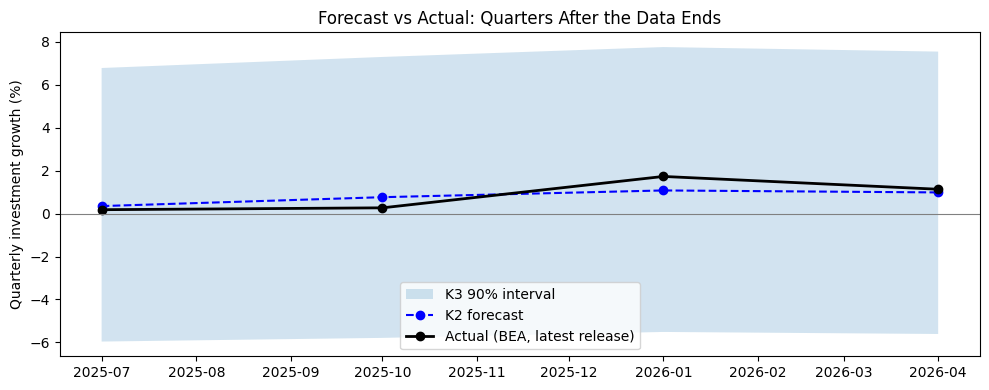

In [46]:
# K5. REAL-DATA CHECK: compare K2/K3 forecasts with actual data released after 2025Q2
# Source: BEA NIPA Table 1.1.6, "Gross private domestic investment" (same series as FRED GPDIC1), via the DBnomics API.
# BEA revises past data, so we compare GROWTH RATES rather than levels.
import json, urllib.request
url = "https://api.db.nomics.world/v22/series/BEA/NIPA-T10106/A006RX-Q?observations=1"
doc = json.load(urllib.request.urlopen(url, timeout=30))["series"]["docs"][0]
new_level = pd.Series(pd.to_numeric(doc["value"], errors="coerce"),
                      index=pd.PeriodIndex(doc["period"], freq="Q").to_timestamp())
actual_new = 100 * np.log(new_level).diff().reindex(future_dates).dropna()
n = len(actual_new)
print(f"Actual data available for {n} of the {H} forecast quarters\n")

check = pd.DataFrame({
    "Actual (%)": actual_new,
    "K2 forecast (%)": 100 * forecast["mean"].iloc[:n].values,
    "K3 90% low (%)": np.percentile(sim_growth[:, :n], 5, axis=0),
    "K3 90% high (%)": np.percentile(sim_growth[:, :n], 95, axis=0),
    "K3 P(decline)": (sim_growth[:, :n] < 0).mean(axis=0),
}, index=actual_new.index)
check["Inside K3 90%?"] = check["Actual (%)"].between(check["K3 90% low (%)"], check["K3 90% high (%)"])
display(check.round(2))

hist_mean = 100 * data_transformed["d_log_GPDIC1"].mean()
print(f"RMSE - K2 forecast: {np.sqrt(((check['Actual (%)'] - check['K2 forecast (%)']) ** 2).mean()):.2f} pp | "
      f"Historical mean ({hist_mean:.2f}%): {np.sqrt(((check['Actual (%)'] - hist_mean) ** 2).mean()):.2f} pp")

plt.figure(figsize=(10, 4))
plt.fill_between(check.index, check["K3 90% low (%)"], check["K3 90% high (%)"], alpha=0.2, label="K3 90% interval")
plt.plot(check.index, check["K2 forecast (%)"], "b--o", label="K2 forecast")
plt.plot(check.index, check["Actual (%)"], "k-o", lw=2, label="Actual (BEA, latest release)")
plt.axhline(0, color="grey", lw=0.8)
plt.ylabel("Quarterly investment growth (%)")
plt.title("Forecast vs Actual: Quarters After the Data Ends")
plt.legend()
plt.tight_layout()


## **Forecast Evaluation Summary**

| Question | Result |
|---|---|
| Does Model 4 + VAR beat the historical mean? (K1, K4) | **Not significantly.** It ties in 2010–2019 (RMSE 2.04 vs 2.03 pp) and is slightly better in 2021–2025 (2.39 vs 2.62 pp), but neither difference is significant (Diebold-Mariano p = 0.98 and 0.37). At 2–4 quarters ahead it does slightly worse than the mean. |
| Is a longer test period needed? | **Yes.** The 18 post-COVID quarters alone suggest Model 4 + VAR wins, but the 40 quarters of 2010–2019 show no advantage. Results from 18 quarters are not reliable on their own. |
| Is the model useful when the drivers are known? | **Yes, in normal times.** With actual drivers, RMSE falls to 1.44 pp in 2010–2019, much better than the mean. After COVID it rises to 3.09 pp, suggesting a structural shift. |
| Are the K2 95% intervals reliable? (K4) | **Yes.** The actual value fell inside 89–95% of the time, close to the 95% target. |
| Are the K3 90% intervals reliable? (K4, K5) | **Too wide.** The actual value fell inside about 94–100% of the time instead of 90%, so K3 overstates uncertainty. |
| Is K3's P(decline) useful? (K4) | **Only one quarter ahead.** Its Brier score beats the naive benchmark at h = 1 in both periods, but not at 2–4 quarters ahead. |
| How did the forecast do on real data after 2025Q2? (K5) | **Well.** All 4 actual quarters (2025Q3–2026Q2) were positive and close to the K2 forecast (RMSE 0.42 vs 0.65 pp for the mean), and all fell inside the K3 interval. With only 4 quarters this is encouraging, not conclusive. |

**Conclusion:** the forecasts give a reasonable central path and reliable 95% intervals (K2), but they are not significantly better than a simple average, and the simulated intervals (K3) are too wide. Model 4 is most useful for explaining investment and for "what if" analysis, not for precise forecasting.

# **What-If Analysis**
Model 4's forecasts are not significantly better than a simple average (K1, K4), but it is well suited to "what if" questions: how investment growth responds when the economy changes.
1. **Sensitivity**: effect of moving one driver by 1 standard deviation, holding the others fixed.
2. **Scenarios**: distribution of investment growth under a recession, a normal quarter, a boom, and a custom scenario (10,000 simulations each).

,1 SD move,Effect on growth (pp),95% CI low,95% CI high
d_log_CP,0.067,0.003,-0.480,0.485
d_log_GDPC1,0.011,1.899,0.987,2.810
d_log_INDPRO,0.018,1.463,0.595,2.332
d_WBAA,0.407,0.320,-0.014,0.653
d_WPUFD,0.936,-0.098,-0.479,0.283


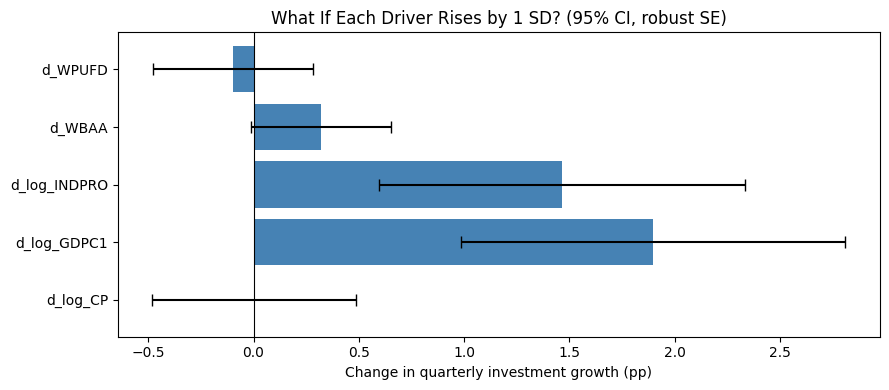

In [47]:
# L1. SENSITIVITY: what if one driver rises by 1 standard deviation (others unchanged)?
m4_robust = model4.get_robustcov_results(cov_type="HC1")
coef = pd.Series(m4_robust.params, index=model4.model.exog_names)[drivers]
se = pd.Series(m4_robust.bse, index=model4.model.exog_names)[drivers]
sd = data_transformed[drivers].std()

sens = pd.DataFrame({
    "1 SD move": sd,
    "Effect on growth (pp)": 100 * coef * sd,
    "95% CI low": 100 * (coef - 1.96 * se) * sd,
    "95% CI high": 100 * (coef + 1.96 * se) * sd,
})
display(sens.round(3))

plt.figure(figsize=(9, 4))
plt.barh(sens.index, sens["Effect on growth (pp)"],
         xerr=[sens["Effect on growth (pp)"] - sens["95% CI low"], sens["95% CI high"] - sens["Effect on growth (pp)"]],
         capsize=4, color="steelblue")
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Change in quarterly investment growth (pp)")
plt.title("What If Each Driver Rises by 1 SD? (95% CI, robust SE)")
plt.tight_layout()


Scenario inputs:


,Recession,Normal,Boom,"Custom: GDP flat, yields +0.5"
d_log_CP,-0.0436,0.0191,0.0754,0.0191
d_log_GDPC1,-0.0018,0.0076,0.0170,0.0000
d_log_INDPRO,-0.0121,0.0069,0.0207,0.0069
d_WBAA,0.3969,-0.0077,-0.4268,0.5000
d_WPUFD,-0.1000,0.6000,1.9163,0.6000



Simulated investment growth by scenario:


,Median (%),5th pct (%),95th pct (%),P(decline)
Recession,-1.06,-4.81,2.67,0.70
Normal,1.77,-1.84,5.25,0.20
Boom,4.18,0.44,7.83,0.03
"Custom: GDP flat, yields +0.5",0.82,-2.93,4.47,0.34


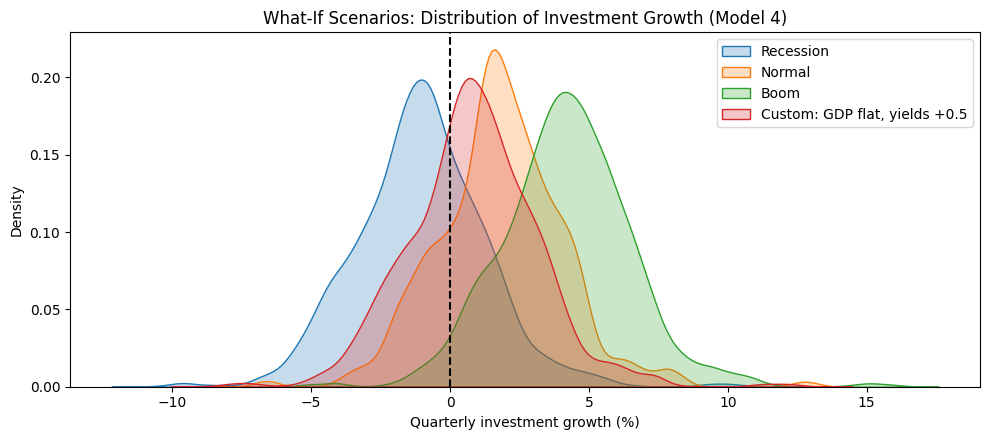

In [48]:
# L2. SCENARIOS: what if the economy is in a recession / normal / boom?
hist = data_transformed[drivers]
scenarios = pd.DataFrame({
    "Recession": hist.quantile(0.10),   # weak quarter: 10th percentile of each driver
    "Normal": hist.median(),
    "Boom": hist.quantile(0.90),        # strong quarter: 90th percentile
})
# Bond yields RISE in recessions and FALL in booms
scenarios.loc["d_WBAA", "Recession"] = hist["d_WBAA"].quantile(0.90)
scenarios.loc["d_WBAA", "Boom"] = hist["d_WBAA"].quantile(0.10)
# Custom scenario - edit these numbers to ask your own "what if"
scenarios["Custom: GDP flat, yields +0.5"] = hist.median()
scenarios.loc[["d_log_GDPC1", "d_WBAA"], "Custom: GDP flat, yields +0.5"] = [0.0, 0.5]
print("Scenario inputs:")
display(scenarios.round(4))

# Simulate: coefficient uncertainty + random past Model 4 errors
N = 10_000
rng = np.random.default_rng(42)
betas = rng.multivariate_normal(m4_robust.params, m4_robust.cov_params(), size=N)
errors = rng.choice(model4.resid, size=N)

results = {}
for name in scenarios.columns:
    x = np.concatenate([[1], scenarios[name].values, [1]])   # intercept, drivers, post_2008
    results[name] = 100 * (betas @ x + errors)

summary = pd.DataFrame({name: {
    "Median (%)": np.median(r),
    "5th pct (%)": np.percentile(r, 5),
    "95th pct (%)": np.percentile(r, 95),
    "P(decline)": (r < 0).mean(),
} for name, r in results.items()}).T
print("\nSimulated investment growth by scenario:")
display(summary.round(2))

plt.figure(figsize=(10, 4.5))
for name, r in results.items():
    sns.kdeplot(r, label=name, fill=True, alpha=0.25)
plt.axvline(0, color="k", ls="--")
plt.xlabel("Quarterly investment growth (%)")
plt.title("What-If Scenarios: Distribution of Investment Growth (Model 4)")
plt.legend()
plt.tight_layout()


Latest investment level: $4,383 billion (annual rate)



,Median change ($bn),5th pct ($bn),95th pct ($bn)
Recession,-46.0,-206.0,119.0
Normal,78.0,-80.0,236.0
Boom,187.0,19.0,357.0
"Custom: GDP flat, yields +0.5",36.0,-127.0,200.0


Gap between boom and recession: about $233 billion of investment (annual rate) in one quarter


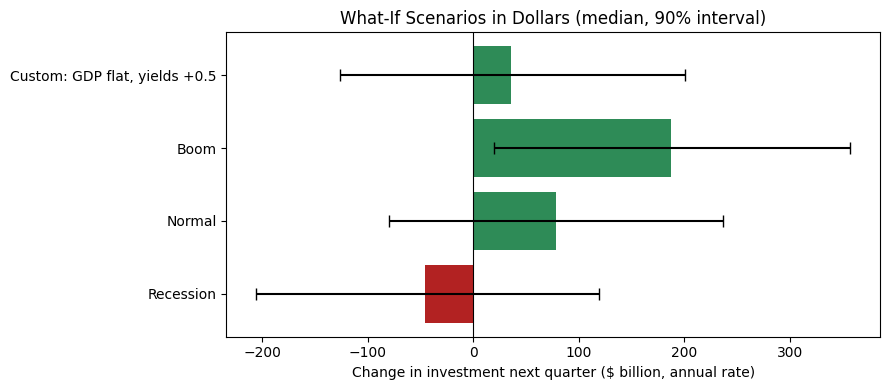

In [49]:
# L3. SCENARIOS IN DOLLARS: how much would business investment change?
# GPDIC1 = real private investment, billions of chained 2017 dollars (seasonally adjusted annual rate)
last_level = data["GPDIC1"].iloc[-1]
print(f"Latest investment level: ${last_level:,.0f} billion (annual rate)\n")

dollar_sims = {name: last_level * (np.exp(r / 100) - 1) for name, r in results.items()}
dollars = pd.DataFrame({name: {
    "Median change ($bn)": np.median(d),
    "5th pct ($bn)": np.percentile(d, 5),
    "95th pct ($bn)": np.percentile(d, 95),
} for name, d in dollar_sims.items()}).T
display(dollars.round(0))

gap = dollars.loc["Boom", "Median change ($bn)"] - dollars.loc["Recession", "Median change ($bn)"]
print(f"Gap between boom and recession: about ${gap:,.0f} billion of investment (annual rate) in one quarter")

plt.figure(figsize=(9, 4))
plt.barh(dollars.index, dollars["Median change ($bn)"],
         xerr=[dollars["Median change ($bn)"] - dollars["5th pct ($bn)"], dollars["95th pct ($bn)"] - dollars["Median change ($bn)"]],
         capsize=4, color=["firebrick" if v < 0 else "seagreen" for v in dollars["Median change ($bn)"]])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Change in investment next quarter ($ billion, annual rate)")
plt.title("What-If Scenarios in Dollars (median, 90% interval)")
plt.tight_layout()


## **Why Businesses Respond This Way**

**Scenarios in dollars** (latest investment ≈ \$4,383 billion, annual rate):

| Scenario | Median change in investment | Chance of decline |
|---|---|---|
| Recession | about **−\$46 billion** | 70% |
| Normal | about +\$78 billion | 20% |
| Boom | about **+\$187 billion** | 3% |
| Custom: GDP flat, yields +0.5 | about +\$36 billion | 34% |

The gap between a boom and a recession is about **\$233 billion** of investment in a single quarter.

**What drives business investment (from L1 sensitivity):**

1. **Businesses invest when demand grows (accelerator effect).** GDP growth (+1.90 pp per 1 SD) and industrial production (+1.46 pp) have by far the largest and only clearly significant effects. Firms expand equipment, buildings and software when sales and output are rising, and cut back quickly when they are not.

2. **Profits alone don't trigger investment.** Corporate profit growth has almost no effect (+0.003 pp, not significant) once GDP and production are included. Having cash is not enough. Firms invest when they expect demand for their products.

3. **Borrowing costs are not the main brake, at least in this data.** The BAA yield effect is small (+0.32 pp) and borderline significant, with the "wrong" (positive) sign. Yields tend to rise when the economy is strong and firms want to borrow more (reverse causality), so this should not be read as "higher rates increase investment."

4. **Producer prices don't matter much.** The PPI effect is small and not significant (−0.10 pp).

**Business takeaway:** investment is one of the first things firms cut when growth weakens, with a 70% chance of decline in a recession versus 3% in a boom. Because demand drives it, policies or conditions that support GDP and production growth matter more for investment than changes in profits or interest rates alone.

*Limitation:* these are national totals, so they show how businesses respond in aggregate, not how individual firms or industries respond.